# RQ4 - Duong cong dao nguoc va du bao suy thoai

Thiet ke chinh (thong nhat voi nhom): mau **1976-06 -> 2025-08**, **train <= 1998-12**, bo 1999, **test >= 2000-01**. Chi giu thang chua suy thoai tai t va du 12 thang tuong lai. Nhan = 1 neu USRECM = 1 trong bat ky thang t+1..t+12. Danh gia AUC + Brier, doi chieu voi hang so = ty le nen cua train (Brier Skill Score). 2022-2026 bao cao rieng (phep thu).

In [1]:
import sys
sys.path.append('..')
import warnings; warnings.filterwarnings('ignore')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from src import config, data_fetch, utils, interactive as ia
pd.options.display.float_format = '{:.4f}'.format
from src import probit_recession as pr

## 1. Du lieu (cache; `--refresh` de tai lai)

In [2]:
spreads, rec_full = data_fetch.fetch_probit_data(use_cache=True)
print(spreads.index.min().date(), spreads.index.max().date(), '| USRECM tu', rec_full.index.min())
spreads.notna().sum()

1976-06-01 2026-09-28 | USRECM tu 1960-01-01 00:00:00


T10Y2Y    12578
T10Y3M    11187
dtype: int64

## 2. Bang thang va mau huan luyen
Spread thang = quan sat hop le cuoi thang (khong ffill).

In [3]:
full, sample = pr.build_probit_monthly(spreads, rec_full, 'T10Y2Y')
print('full', len(full), '| sample', len(sample), sample.index.min(), '->', sample.index.max())
sample.groupby('inverted')['recession_ahead'].agg(months='size', pos='sum', rate='mean')

full 603 | sample 527 1976-06 -> 2025-08


,months,pos,rate
inverted,,,
0,445,34.0000,0.0764
1,82,37.0000,0.4512


## 3. Probit chinh: 10Y-2Y, train <= 1998-12 / test >= 2000-01

In [4]:
fixed, res, p_fixed = pr.evaluate_fixed_split(sample, 'spread')
print(res.summary().tables[1])
pd.Series(fixed)

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.5346      0.151     -3.545      0.000      -0.830      -0.239
spread        -2.5100      0.376     -6.684      0.000      -3.246      -1.774


n_train                  238
n_test                   277
train_positive            35
test_positive             36
train_start          1976-06
train_end            1998-12
test_start           2000-01
test_end             2025-08
train_base_rate       0.1471
coef_const           -0.5346
coef                 -2.5100
pvalue_coef           0.0000
mcfadden_r2_train     0.5593
auc                   0.8220
brier                 0.1307
brier_naive           0.1134
bss                  -0.1530
dtype: object

## 4. So sanh mo hinh (cung mau test)

In [5]:
dummy,_,_ = pr.evaluate_fixed_split(sample, 'inverted')
full3, sample3 = pr.build_probit_monthly(spreads, rec_full, 'T10Y3M')
alt3,_,_ = pr.evaluate_fixed_split(sample3, 'spread')
exp, p_exp = pr.evaluate_expanding(sample, 'spread')
cols=['n_train','train_positive','auc','brier','brier_naive','bss']
tab = pd.DataFrame({'10Y-2Y (co dinh)':fixed,'Dummy dao nguoc':dummy,'10Y-3M (co dinh, train tu 1982-12)':alt3,'10Y-2Y (expanding)':exp}).T
tab[[c for c in cols if c in tab]]

,n_train,train_positive,auc,brier,brier_naive,bss
10Y-2Y (co dinh),238,35,0.8220,0.1307,0.1134,-0.1530
Dummy dao nguoc,238,35,0.6100,0.1388,0.1134,-0.2246
"10Y-3M (co dinh, train tu 1982-12)",184,12,0.8445,0.1399,0.1173,-0.1929
10Y-2Y (expanding),NaN,NaN,0.8088,0.1296,0.1171,-0.1064


AUC ~0,8: spread **xep hang** dung cac thang truoc suy thoai. Brier khong thang hang so (BSS < 0): xac suat tuyet doi chua hieu chinh tot, he so khong on dinh (expanding: −2,5 → −1,4).

In [6]:
print('he so expanding: dau', round(exp['coef_first'],3), '| cuoi', round(exp['coef_last'],3))

he so expanding: dau -2.514 | cuoi -1.39


## 5. Xac suat ngoai mau 2000-2025

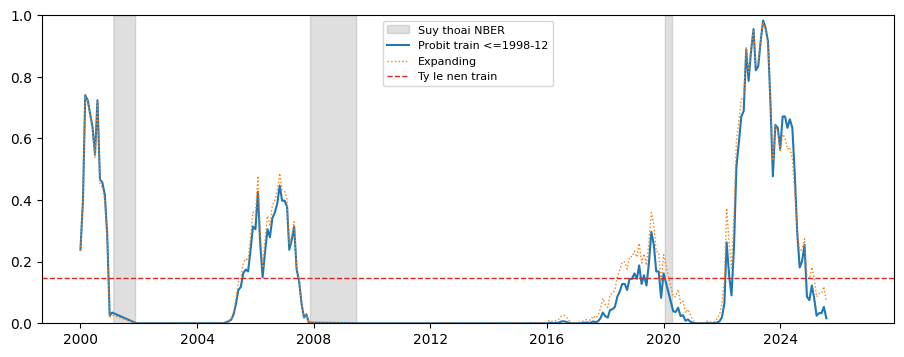

In [7]:
rec_t = full['recession'].loc['2000-01':]
fig, ax = plt.subplots(figsize=(11,4))
ax.fill_between(rec_t.index.to_timestamp(), 0, rec_t.values, color='grey', alpha=.25, step='mid', label='Suy thoai NBER')
ax.plot(p_fixed.index.to_timestamp(), p_fixed.values, label='Probit train <=1998-12')
ax.plot(p_exp.index.to_timestamp(), p_exp.values, ls=':', lw=1, label='Expanding')
ax.axhline(fixed['train_base_rate'], color='C3', ls='--', lw=1, label='Ty le nen train')
ax.set_ylim(0,1); ax.legend(fontsize=8); plt.show()

## 6. Phep thu 2022-2026 (mo hinh co dinh)

In [8]:
seg = pr.stress_path(full, res, config.PROBIT_STRESS_START)
lab = seg['recession_ahead'].notna()
print('thang', len(seg), '| co nhan', lab.sum(), '| suy thoai thuc te', int(seg.loc[lab,'recession_ahead'].sum()))
print('P trung binh', round(seg.loc[lab,'prob'].mean(),3), '| max', round(seg['prob'].max(),3), seg['prob'].idxmax(), '| so thang P>0.5:', int((seg['prob']>0.5).sum()))
print('Brier mo hinh', round(((seg.loc[lab,'prob']-seg.loc[lab,'recession_ahead'])**2).mean(),4), '| Brier hang so', round(((fixed['train_base_rate']-seg.loc[lab,'recession_ahead'])**2).mean(),4))

thang 56 | co nhan 44 | suy thoai thuc te 0
P trung binh 0.466 | max 0.983 2023-06 | so thang P>0.5: 23
Brier mo hinh 0.3241 | Brier hang so 0.0216


## 7. Dao nguoc va thang hien tai

In [9]:
inv = pr.flag_inversion_periods(full['spread'].dropna())
display(inv)
cur = float(full['spread'].iloc[-1])
print('thang', full.index[-1], 'spread', cur, '-> P =', round(float(pr.recession_probability(res, cur)),4), '(tam thoi neu thang chua ket thuc)')

,start,end,length_months
0,1978-08,1980-05,21
1,1980-09,1981-10,13
2,1982-01,1982-05,4
3,1982-06,1982-07,1
4,1989-01,1989-06,5
5,1989-08,1989-10,2
6,1998-06,1998-07,1
7,2000-02,2000-12,10
8,2005-12,2006-03,3
9,2006-06,2006-07,1


thang 2026-08 spread 0.41 -> P = 0.0589 (tam thoi neu thang chua ket thuc)


## 8. Tuong tac 2D / 3D

In [10]:
oos = pd.DataFrame({'prob_fixed': p_fixed, 'prob_expanding': p_exp}).join(full[['spread','recession','recession_ahead']], how='left')
oos.index = oos.index.astype(str)
rec_plot = rec_full.copy()
ia.fig_probit_2d(oos, fixed['train_base_rate'], rec_plot).show()

In [11]:
ia.fig_probit_3d(oos).show()

In [12]:
ia.fig_probit_curve(fixed['coef_const'], fixed['coef'], oos).show()

## 9. Do nhay: thiet ke cu (cua so 2000-2026, split 2021-12-31)

In [13]:
import json
json.load(open('../outputs/rq4_probit_summary_window2000_split2021.json'))

{'coef_spread': -0.28309480968016887,
 'pvalue_spread': 0.001165447442639031,
 'mcfadden_r2': 0.03456658540525792,
 'auc_full': 0.6375512295081966,
 'auc_train': 0.7321875,
 'auc_test': None,
 'current_spread': 0.6400000000000006,
 'current_prob': 0.23395486363996115,
 'confusion_matrix': [[244, 0], [64, 0]],
 'brier_full': 0.15958487712863598,
 'brier_test': 0.27908542707043354,
 'brier_test_naive_benchmark': 0.05876951331496785}